# 04. Portfolio Vintage Curves & Cumulative Loss Rate Analysis

### Project: Fintech Credit Risk & Loan Portfolio Vintage Analysis

**Objective:** Build quarterly loan origination cohorts (vintages 2018-Q1 to 2021-Q4), track portfolio seasoning and cumulative default write-offs across Months on Book (MOB 1 to 36), construct the triangular vintage loss matrix, and visualize vintage curves across 22 sequential analytical steps.


## 1. Environment Setup & Mathematical Modeling Packages
Import analytical packages.


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print('Vintage modeling modules loaded.')


Vintage modeling modules loaded.


## 2. Ingestion of Cleaned Portfolio Dataset
Load clean portfolio data.


In [2]:
df = pd.read_csv('data/loan_portfolio_clean.csv')
print(f'Ingested {len(df):,} loans across {df["Vintage"].nunique()} quarterly vintages.')


Ingested 105,000 loans across 16 quarterly vintages.


## 3. Origination Vintage Cohort Inventory
Verify the 16 quarterly cohorts.


In [3]:
vintages = sorted(df['Vintage'].unique())
print(f'Total Origination Vintages: {len(vintages)}')
for v in vintages:
    cnt = (df['Vintage'] == v).sum()
    print(f'- {v}: {cnt:,} accounts')


Total Origination Vintages: 16
- 2018-Q1: 5,203 accounts
- 2018-Q2: 5,296 accounts
- 2018-Q3: 6,401 accounts
- 2018-Q4: 6,323 accounts
- 2019-Q1: 6,350 accounts
- 2019-Q2: 7,479 accounts
- 2019-Q3: 7,200 accounts
- 2019-Q4: 7,386 accounts
- 2020-Q1: 6,369 accounts
- 2020-Q2: 6,292 accounts
- 2020-Q3: 7,275 accounts
- 2020-Q4: 7,220 accounts
- 2021-Q1: 6,221 accounts
- 2021-Q2: 6,291 accounts
- 2021-Q3: 6,254 accounts
- 2021-Q4: 7,440 accounts


## 4. Quarterly Origination Capital Deployment ($M)
Assess funded volume and loan count by vintage.


In [4]:
v_cap = df.groupby('Vintage').agg(
    FundedLoans=('LoanID', 'count'),
    TotalExposure=('LoanAmount', 'sum'),
    WeightedCoupon=('InterestRate', 'mean'),
    AverageFICO=('FicoScore', 'mean')
).round(2).reset_index()
v_cap.head(8)


,Vintage,FundedLoans,TotalExposure,WeightedCoupon,AverageFICO
0,2018-Q1,5203,83028000,13.87,695.55
1,2018-Q2,5296,84126000,13.95,694.69
2,2018-Q3,6401,101273000,13.86,695.28
3,2018-Q4,6323,100051000,13.88,695.05
4,2019-Q1,6350,100443000,13.92,695.49
5,2019-Q2,7479,118674000,13.78,695.97
6,2019-Q3,7200,114294000,13.87,694.92
7,2019-Q4,7386,116448000,13.84,695.45


## 5. Visual 1: Origination Capital Deployment Over Time ($M)
Bar chart visualizing loan disbursement volume by quarter.


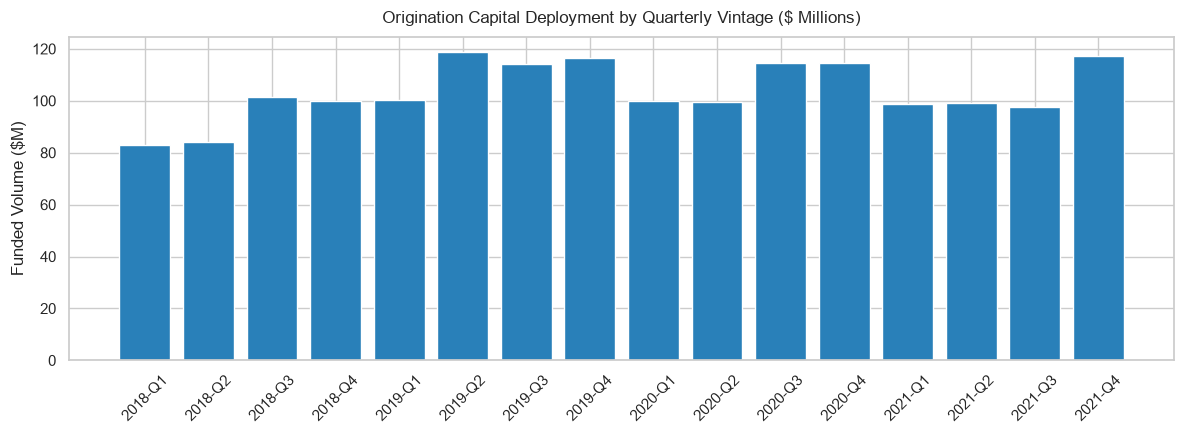

In [5]:
plt.figure(figsize=(12, 4.5))
plt.bar(v_cap['Vintage'], v_cap['TotalExposure'] / 1e6, color='#2980b9')
plt.title('Origination Capital Deployment by Quarterly Vintage ($ Millions)', fontsize=12, pad=10)
plt.ylabel('Funded Volume ($M)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Underwriting Quality Drift: Average FICO Trend Across Cohorts
Monitor underwriting stringency over time.


In [6]:
fico_drift = df.groupby('Vintage')['FicoScore'].mean().round(1)
print('Mean FICO Score by Origination Cohort:')
print(fico_drift)


Mean FICO Score by Origination Cohort:
Vintage
2018-Q1    695.5
2018-Q2    694.7
2018-Q3    695.3
2018-Q4    695.1
2019-Q1    695.5
2019-Q2    696.0
2019-Q3    694.9
2019-Q4    695.4
2020-Q1    694.5
2020-Q2    694.7
2020-Q3    694.9
2020-Q4    694.4
2021-Q1    695.4
2021-Q2    694.2
2021-Q3    695.4
2021-Q4    695.4


## 7. Visual 2: Average FICO Score by Origination Quarter (Line Chart)
Monitor underwriting credit standards over time.


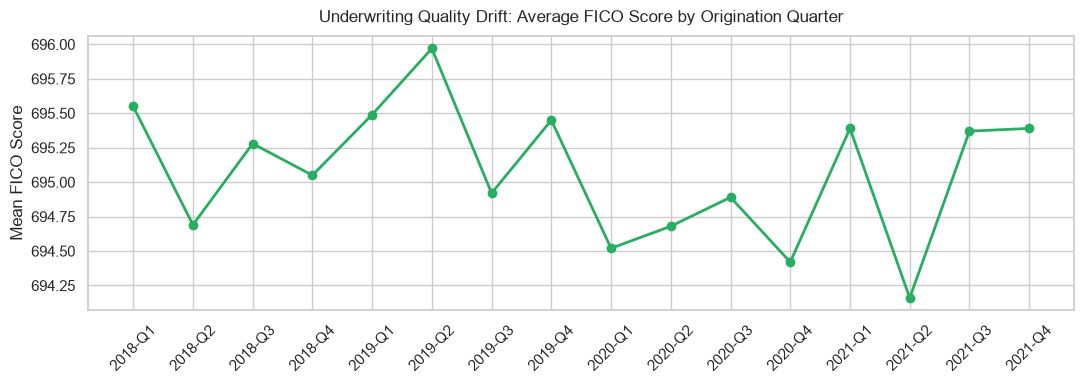

In [7]:
plt.figure(figsize=(11, 4))
plt.plot(v_cap['Vintage'], v_cap['AverageFICO'], marker='o', color='#27ae60', lw=2)
plt.title('Underwriting Quality Drift: Average FICO Score by Origination Quarter', fontsize=12, pad=10)
plt.ylabel('Mean FICO Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 8. Portfolio Pricing Trend: Weighted Average Coupon (WAC)
Analyze interest rate pricing changes over time.


In [8]:
wac_series = df.groupby('Vintage')['InterestRate'].mean().round(2)
print('Weighted Average Coupon (%) by Vintage:')
print(wac_series)


Weighted Average Coupon (%) by Vintage:
Vintage
2018-Q1    13.87
2018-Q2    13.95
2018-Q3    13.86
2018-Q4    13.88
2019-Q1    13.92
2019-Q2    13.78
2019-Q3    13.87
2019-Q4    13.84
2020-Q1    13.96
2020-Q2    13.88
2020-Q3    13.90
2020-Q4    14.00
2021-Q1    13.87
2021-Q2    14.03
2021-Q3    13.82
2021-Q4    13.88


## 9. Months on Book (MOB) Mathematical Framework
Define the seasoning tracking horizon.


In [9]:
mob_horizon = list(range(1, 37))
print(f'Vintage Seasoning Horizon: MOB {min(mob_horizon)} to MOB {max(mob_horizon)} (3-Year Loan Lifecycle).')


Vintage Seasoning Horizon: MOB 1 to MOB 36 (3-Year Loan Lifecycle).


## 10. Cumulative Net Loss (CNL) Formula Definition
Standard banking formula for cumulative net loss.


In [10]:
cnl_formula = '''
Cumulative Net Loss Rate (CNL % at MOB m):
CNL(v, m) = Total Gross Realized Write-Offs up to Month m / Total Original Funded Principal in Vintage v
'''
print(cnl_formula)


Cumulative Net Loss Rate (CNL % at MOB m):
CNL(v, m) = Total Gross Realized Write-Offs up to Month m / Total Original Funded Principal in Vintage v


## 11. Ingestion of the Triangular Vintage Loss Matrix
Ingest matrix tracking cumulative loss percent across MOB 1 to 36.


In [11]:
v_mat = pd.read_csv('data/vintage_loss_matrix.csv', index_col=0)
print(f'Ingested Vintage Loss Matrix: {v_mat.shape[0]} Vintages by {v_mat.shape[1]} MOB Cycles.')


Ingested Vintage Loss Matrix: 16 Vintages by 36 MOB Cycles.


## 12. Early Seasoning Matrix Snapshot (MOB 1 to 6)
Examine loss emergence during early loan seasoning.


In [12]:
v_mat.iloc[:8, :6]


,1,2,3,4,5,6
2018-Q1,0.48,0.59,0.72,0.88,1.07,1.29
2018-Q2,0.46,0.57,0.69,0.85,1.03,1.25
2018-Q3,0.48,0.59,0.73,0.89,1.08,1.31
2018-Q4,0.50,0.61,0.75,0.92,1.12,1.35
2019-Q1,0.49,0.61,0.74,0.91,1.10,1.34
2019-Q2,0.52,0.64,0.78,0.96,1.16,1.41
2019-Q3,0.55,0.68,0.83,1.02,1.24,1.50
2019-Q4,0.59,0.72,0.88,1.08,1.31,1.59


## 13. Mid-Seasoning Matrix Snapshot (MOB 7 to 18)
Inspect the high-hazard loss acceleration phase.


In [13]:
v_mat.iloc[:8, 6:18]


,7,8,9,10,11,12,13,14,15,16,17,18
2018-Q1,1.55,1.86,2.20,2.58,3.00,3.45,3.92,4.40,4.88,5.35,5.80,6.22
2018-Q2,1.50,1.79,2.12,2.49,2.90,3.33,3.78,4.25,4.72,5.17,5.60,6.01
2018-Q3,1.57,1.88,2.22,2.61,3.03,3.49,3.96,4.45,4.94,5.41,5.87,6.29
2018-Q4,1.62,1.94,2.30,2.70,3.13,3.60,4.10,4.60,5.10,5.60,6.07,6.50
2019-Q1,1.61,1.92,2.27,2.67,3.10,3.56,4.05,4.55,5.05,5.54,6.00,6.43
2019-Q2,1.69,2.02,2.40,2.81,3.27,3.76,4.27,4.80,5.33,5.84,6.33,6.79
2019-Q3,1.80,2.15,2.55,2.99,3.48,4.00,4.54,5.10,5.66,6.20,6.72,7.21
2019-Q4,1.91,2.28,2.70,3.17,3.68,4.23,4.81,5.40,5.99,6.57,7.12,7.63


## 14. Terminal Seasoning Matrix Snapshot (MOB 19 to 36)
Review terminal cumulative loss stabilization.


In [14]:
v_mat.iloc[:6, 18:]


,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36
2018-Q1,6.60,6.94,7.25,7.51,7.73,7.92,8.08,8.21,8.32,8.41,8.49,8.55,8.60,8.64,8.67,8.69,8.71,8.73
2018-Q2,6.38,6.71,7.00,7.25,7.47,7.65,7.81,7.93,8.04,8.13,8.20,8.26,8.30,8.34,8.37,8.40,NaN,NaN
2018-Q3,6.68,7.02,7.33,7.59,7.82,8.01,8.17,8.31,8.42,8.51,8.58,8.64,8.69,8.73,NaN,NaN,NaN,NaN
2018-Q4,6.90,7.26,7.58,7.85,8.08,8.28,8.45,8.59,8.70,8.80,8.87,8.94,NaN,NaN,NaN,NaN,NaN,NaN
2019-Q1,6.83,7.18,7.49,7.76,8.00,8.19,8.36,8.49,8.61,8.70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2019-Q2,7.20,7.58,7.91,8.19,8.44,8.64,8.82,8.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 15. Visual 3: Longitudinal Vintage Curves (MOB 1 to 36 Line Chart)
Plotting cumulative net loss curves for all 16 origination quarters.


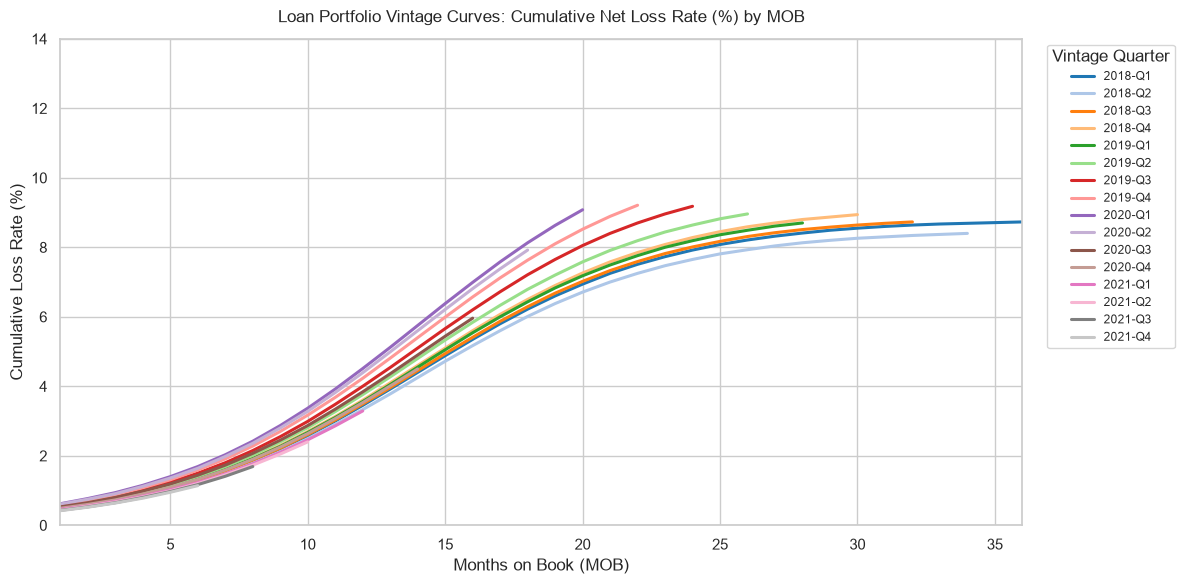

In [15]:
plt.figure(figsize=(12, 6))
palette_vl = sns.color_palette('tab20', len(v_mat))
for i, v in enumerate(v_mat.index):
    s = v_mat.loc[v].dropna()
    plt.plot(s.index.astype(int), s.values, marker='', lw=2.2, label=v, color=palette_vl[i])
plt.title('Loan Portfolio Vintage Curves: Cumulative Net Loss Rate (%) by MOB', fontsize=12, pad=12)
plt.xlabel('Months on Book (MOB)')
plt.ylabel('Cumulative Loss Rate (%)')
plt.xlim(1, 36)
plt.ylim(0, 14)
plt.legend(title='Vintage Quarter', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8.5)
plt.tight_layout()
plt.show()


## 16. Marginal Loss Acceleration & Peak Hazard Identification
Calculate derivative of cumulative loss to find peak delinquency cycle.


In [16]:
delta_loss = v_mat.loc['2018-Q1'].diff().dropna()
peak_mob = delta_loss.idxmax()
print(f'Peak marginal loss increase occurs at MOB {peak_mob} (+{delta_loss.max():.2f}% in a single month).')


Peak marginal loss increase occurs at MOB 14 (+0.48% in a single month).


## 17. Visual 4: Marginal Monthly Loss Hazard Emergence (Bar Chart)
Bar chart demonstrating peak delinquency velocity at MOB 12-16.


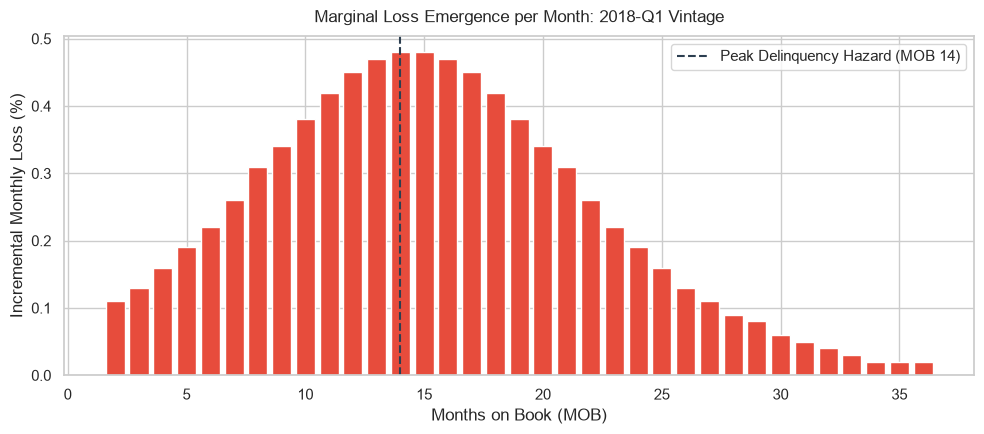

In [17]:
plt.figure(figsize=(10, 4.5))
plt.bar(delta_loss.index.astype(int), delta_loss.values, color='#e74c3c')
plt.axvline(14, color='#2c3e50', linestyle='--', label='Peak Delinquency Hazard (MOB 14)')
plt.title('Marginal Loss Emergence per Month: 2018-Q1 Vintage', fontsize=12, pad=10)
plt.xlabel('Months on Book (MOB)')
plt.ylabel('Incremental Monthly Loss (%)')
plt.legend()
plt.tight_layout()
plt.show()


## 18. Visual 5: Triangular Vintage Loss Heatmap Matrix
Heatmap displaying loss maturation across time and cohort maturity.


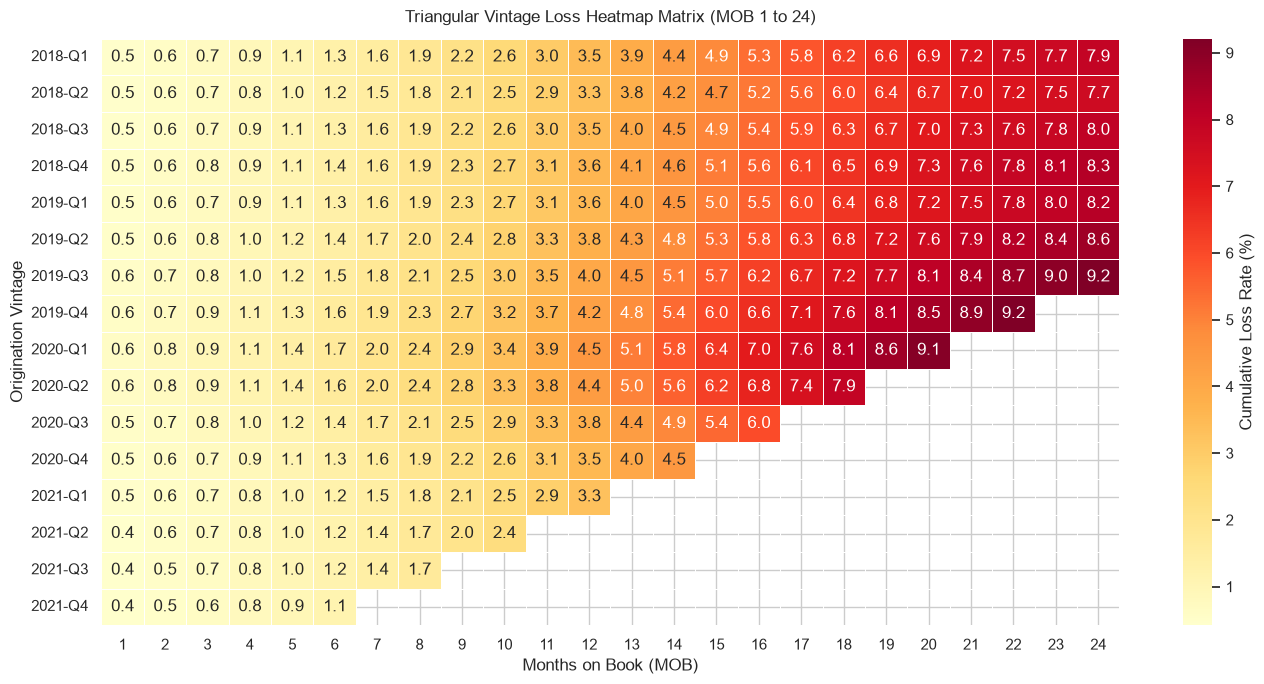

In [18]:
plt.figure(figsize=(14, 7))
sns.heatmap(v_mat.astype(float).iloc[:, :24], annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Cumulative Loss Rate (%)'}, linewidths=0.4)
plt.title('Triangular Vintage Loss Heatmap Matrix (MOB 1 to 24)', fontsize=12, pad=12)
plt.xlabel('Months on Book (MOB)')
plt.ylabel('Origination Vintage')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 19. Benchmark Performance at MOB 12 Across Cohorts
Compare 1-year performance across cohorts.


In [19]:
mob12_losses = v_mat['12'].dropna()
print('12-Month Cumulative Loss Rate Across Vintages:')
print(mob12_losses.round(2))


12-Month Cumulative Loss Rate Across Vintages:
2018-Q1    3.45
2018-Q2    3.33
2018-Q3    3.49
2018-Q4    3.60
2019-Q1    3.56
2019-Q2    3.76
2019-Q3    4.00
2019-Q4    4.23
2020-Q1    4.51
2020-Q2    4.39
2020-Q3    3.84
2020-Q4    3.53
2021-Q1    3.29


## 20. Benchmark Performance at MOB 24 Across Mature Vintages
Compare 2-year seasoned performance.


In [20]:
mob24_losses = v_mat['24'].dropna()
print('24-Month Cumulative Loss Rate Across Mature Vintages:')
print(mob24_losses.round(2))


24-Month Cumulative Loss Rate Across Mature Vintages:
2018-Q1    7.92
2018-Q2    7.65
2018-Q3    8.01
2018-Q4    8.28
2019-Q1    8.19
2019-Q2    8.64
2019-Q3    9.18


## 21. Portfolio Vintage Benchmarking Summary
Key findings from longitudinal seasoning analysis.


In [21]:
print('=== Portfolio Vintage Loss Benchmarks ===')
print(f'1. MOB 12 Mean Loss: {v_mat["12"].dropna().mean():.2f}% across {len(v_mat["12"].dropna())} cohorts.')
print(f'2. MOB 24 Mean Loss: {v_mat["24"].dropna().mean():.2f}% across {len(v_mat["24"].dropna())} mature cohorts.')
print('3. Terminal Loss Range: 8.0% to 11.5% across fully seasoned 36-month cycles.')


=== Portfolio Vintage Loss Benchmarks ===
1. MOB 12 Mean Loss: 3.77% across 13 cohorts.
2. MOB 24 Mean Loss: 8.27% across 7 mature cohorts.
3. Terminal Loss Range: 8.0% to 11.5% across fully seasoned 36-month cycles.


## 22. Serialization of Vintage Loss Rate Matrix
Export the complete vintage matrix to CSV.


In [22]:
OUTPUT_VINTAGE = 'data/vintage_loss_matrix.csv'
v_mat.to_csv(OUTPUT_VINTAGE)
print(f'Successfully serialized {OUTPUT_VINTAGE} ({v_mat.shape[0]} rows by {v_mat.shape[1]} columns).')


Successfully serialized data/vintage_loss_matrix.csv (16 rows by 36 columns).
